# Class-label definitions

The dataset uses the following encodings:

- **Gallstone Status:** `0 = Yes`, `1 = No` (target variable)
- **Gender:** `0 = Male`, `1 = Female`
- **Comorbidity:** `0 = No comorbidities present`, `1 = One comorbid condition`, `2 = Two comorbid conditions`, `3 = Three or more comorbid conditions`
- **Coronary Artery Disease (CAD):** `0 = No`, `1 = Yes`
- **Hypothyroidism:** `0 = No`, `1 = Yes`
- **Hyperlipidemia:** `0 = No`, `1 = Yes`
- **Diabetes Mellitus (DM):** `0 = No`, `1 = Yes`
- **Hepatic Fat Accumulation (HFA):** `0 = No fat accumulation`, `1 = Grade 1 (mild)`, `2 = Grade 2 (moderate)`, `3 = Grade 3 (severe)`, `4 = Grade 4 (very severe)`

Because `Gallstone Status = 1` means **No gallstones**, evaluation metrics using the default positive class describe performance for the no-gallstone class.

# Gallstone disease prediction

This notebook uses patient health data to predict whether gallstones are present. The main model is XGBoost. The notebook also uses charts and SHAP explanations to show which features affect the predictions.

The aim is to build a useful classification example and to make the model results easier to understand.

## Dataset

The data comes from the UCI Gallstone-1 dataset. It contains 319 patient records and 38 predictor columns. The columns include demographic information, body measurements, medical conditions, hepatic fat accumulation, and laboratory results.

The dataset is loaded from `data/dataset-uci/dataset-uci.csv`. The class definitions above are kept visible because the numeric values have a specific medical meaning.

## Notebook workflow

The notebook is organised into these steps:

1. Import the Python libraries used by the project.
2. Load and preprocess the dataset.
3. Separate the target column from the predictor columns.
4. Split the data into training and test sets.
5. Train the XGBoost classifier and calculate evaluation metrics.
6. Create graphs and SHAP explanations for the model.


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
from IPython.display import display

print("NumPy:", np.__version__)
print("XGBoost:", xgb.__version__)
print("SHAP:", shap.__version__)

NumPy: 1.26.4
XGBoost: 3.4.2
SHAP: 0.48.0


## Loading and processing the data

`DatasetLoader` is responsible for reading the CSV file and preparing the data. `DataProcessor` is used after loading to organise the data and separate the target from the predictors.

The target is `Gallstone Status`. The remaining columns are used as model inputs. The loader strips whitespace from column names and drops missing rows. The processor checks numeric values and validates the target. No scaling is needed for XGBoost.

In [53]:

class DatasetLoader:
    """Load and clean the Gallstone dataset."""

    def __init__(self, source):
        self.source = source

    def load(self):
        """Read the dataset CSV file."""
        return pd.read_csv(self.source)

    def preprocess(self, data):
        """Remove missing rows and extra spaces in column names."""
        data = data.copy()
        data.columns = data.columns.str.strip()
        print("Missing values before cleaning:", data.isna().sum().sum())
        cleaned = data.dropna()
        print("Rows removed:", len(data) - len(cleaned))
        return cleaned

    def run(self):
        """Load and preprocess the data."""
        data = self.load()
        return self.preprocess(data)

In [54]:
class DataProcessor:
    """Prepare the data for XGBoost."""

    def __init__(self, data):
        self.data = data

    def process(self):
        """Make sure all columns contain numeric values."""
        data = self.data.apply(pd.to_numeric)
        if not np.isfinite(data.to_numpy()).all():
            raise ValueError("Dataset contains missing or infinite values.")
        if set(data["Gallstone Status"].unique()) != {0, 1}:
            raise ValueError("Expected both target classes: 0 and 1.")
        return data

    def split_features_and_target(self, target_column="Gallstone Status"):
        """Separate the target from the input features."""
        features = self.data.drop(columns=[target_column])
        target = self.data[target_column]
        return features, target

In [55]:
class XGBoostModelTrainer:
    """Train and evaluate gallstone disease classification.

    Target encoding is kept unchanged:
        0 = Gallstones present
        1 = No gallstones

    Gallstone presence (class 0) is the clinical positive class for
    precision, sensitivity/recall, F1 and ROC-AUC.
    """

    def __init__(self, data):
        self.data = data

    def train(self):
        """Make one stratified hold-out split and fit an XGBClassifier."""
        processor = DataProcessor(self.data)
        features, target = processor.split_features_and_target()

        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            features, target, test_size=0.2, random_state=42, stratify=target)

        print(f"Training set shape: {self.X_train.shape}, "
            f"Test set shape: {self.X_test.shape}")

        model = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss",
            n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
        
        model.fit(self.X_train, self.y_train)

        return model

    def evaluate(self, model):
        """Evaluate gallstones (class 0) as the positive clinical outcome."""
        predictions = model.predict(self.X_test)
        gallstone_index = list(model.classes_).index(0)
        gallstone_probabilities = model.predict_proba(self.X_test)[:, gallstone_index]
        gallstone_target = (self.y_test == 0).astype(int)

        metrics = {"accuracy": accuracy_score(self.y_test, predictions),
            "precision_gallstones": precision_score(
                self.y_test, predictions, pos_label=0, zero_division=0),
            "sensitivity_gallstones": recall_score(
                self.y_test, predictions, pos_label=0, zero_division=0),
            "specificity_gallstones": recall_score(
                self.y_test, predictions, pos_label=1, zero_division=0),
            "f1_gallstones": f1_score(
                self.y_test, predictions, pos_label=0, zero_division=0),
            "roc_auc_gallstones": roc_auc_score(
                gallstone_target, gallstone_probabilities)}

        print("\nClassification report (0 = Gallstones, 1 = No gallstones):")
        print(classification_report(self.y_test, predictions, labels=[0, 1],
            target_names=["Gallstones", "No gallstones"], zero_division=0))
        print("\nConfusion matrix (rows = actual; columns = predicted; order = [0, 1]):")
        print(confusion_matrix(self.y_test, predictions, labels=[0, 1]))

        return metrics

    def predict(self, model, new_data):
        """Predict original labels and provide probabilities for both classes."""

        features = pd.DataFrame(new_data).copy()
        expected_columns = list(self.X_train.columns)
        missing = [column for column in expected_columns if column not in features.columns]
        unexpected = [column for column in features.columns if column not in expected_columns]

        if missing or unexpected:
            raise ValueError(
                f"Missing columns: {missing}; unexpected columns: {unexpected}")

        features = features[expected_columns]

        probabilities = model.predict_proba(features)

        return {"predictions": model.predict(features),"probability_gallstones": probabilities[:, list(model.classes_).index(0)], "probability_no_gallstones": probabilities[:, list(model.classes_).index(1)],}

    def explain(self, model):
        """Explain the predicted probability of gallstones (class 0)."""
        background = self.X_train.sample(n=min(100, len(self.X_train)), random_state=42)
        gallstone_index = list(model.classes_).index(0)

        def predict_gallstones(values):
            features = pd.DataFrame(values, columns=self.X_train.columns)
            return model.predict_proba(features)[:, gallstone_index]

        explainer = shap.Explainer(predict_gallstones, background,
                                  algorithm="permutation", seed=42)
        explanations = explainer(self.X_test, max_evals=5 * (2 * self.X_test.shape[1] + 1))

        # Check that the SHAP contributions reconstruct the predicted probability.
        reconstructed = explanations.base_values + explanations.values.sum(axis=1)
        np.testing.assert_allclose(reconstructed, predict_gallstones(self.X_test), atol=1e-5)
        return explanations

    def run(self):
        """Fit, evaluate and explain the model; keep the same return signature."""
        model = self.train()
        metrics = self.evaluate(model)
        explanations = self.explain(model)

        return model, metrics, explanations


In [56]:
class DataVisualizer:
    """
    Create exploratory and evaluation plots with readable layouts.
    Template from XGBoost and SHAP documentation, adapted for gallstone disease classification.
    """

    def __init__(self, data):
        """Initialize visualizer with a copy of the dataset."""
        self.data = (
            data.copy()

            if isinstance(data, pd.DataFrame)
            else pd.DataFrame(data)
        )

    def plot_target_distribution(self, target="Gallstone Status"):
        """Plot the number of records in each target class."""
        if target not in self.data.columns:
            raise ValueError(f"Target column not found: {target}")

        counts = self.data[target].value_counts().sort_index()
        if counts.empty:
            raise ValueError("Target column contains no valid values.")

        figure, axis = plt.subplots(
            figsize=(8, 4),
            layout="constrained")

        bars = axis.bar(counts.index.astype(str), counts.values,
            color="steelblue", edgecolor="black", alpha=0.85, width=0.6)

        axis.set_title(f"Distribution of {target}",
            fontsize=14, fontweight="bold", pad=15)
        axis.set_xlabel(target, fontsize=11, labelpad=10)
        axis.set_ylabel("Number of records", fontsize=11)
        axis.tick_params(axis="both", labelsize=10)

        if len(counts) > 5:
            plt.setp(axis.get_xticklabels(), rotation=30, ha="right")

        axis.set_ylim(0, max(counts.values) * 1.15)

        for bar in bars:
            height = bar.get_height()
            axis.annotate(
                f"{int(height)}", xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points", ha="center",
                va="bottom", fontsize=10)

        axis.grid(axis="y", linestyle="--", alpha=0.3)
        axis.set_axisbelow(True)

        return figure

    def plot_feature_distribution(self, feature, bins=20):
        """Plot a numeric histogram or categorical bar chart."""
        if feature not in self.data.columns:
            raise ValueError(f"Feature column not found: {feature}")

        values = self.data[feature].dropna()

        if values.empty:
            raise ValueError(f"No valid values found for {feature}")

        if pd.api.types.is_numeric_dtype(values):
            figure, axis = plt.subplots(figsize=(8, 4), layout="constrained")

            axis.hist(values, bins=bins, color="steelblue",
                edgecolor="black", alpha=0.8)

            axis.set_xlabel(feature, fontsize=11, labelpad=10)
            axis.set_ylabel("Number of records", fontsize=11)

            axis.grid(axis="y", linestyle="--", alpha=0.3)

        else:
            counts = values.value_counts().head(20)

            figure, axis = plt.subplots(figsize=(8, 4), layout="constrained")

            bars = axis.barh(counts.index.astype(str), counts.values,
                color="steelblue", edgecolor="black", alpha=0.85)

            axis.invert_yaxis()
            axis.set_xlabel("Number of records", fontsize=11)
            axis.set_ylabel(feature, fontsize=11)
            axis.tick_params(axis="y", labelsize=9, pad=5)
            axis.set_xlim(0, max(counts.values) * 1.15)

            for bar in bars:
                width = bar.get_width()
                axis.annotate(f"{int(width)}",xy=(
                        width, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0),textcoords="offset points",
                    ha="left", va="center", fontsize=9)

            axis.grid(axis="x", linestyle="--", alpha=0.3)

        axis.set_title(f"Distribution of {feature}",fontsize=14,
            fontweight="bold", pad=15)
        axis.tick_params(axis="x", labelsize=10)
        axis.set_axisbelow(True)

        return figure

    def plot_correlation_matrix(self):
        """Plot correlations between numeric features."""
        numeric_data = self.data.select_dtypes(include="number")

        if numeric_data.empty:
            raise ValueError("At least one numeric column is required.")

        correlations = numeric_data.corr()
        labels = correlations.columns.tolist()
        n_features = len(labels)
        figure_size = max(10, n_features * 0.6)
        figure, axis = plt.subplots(
            figsize=(figure_size, figure_size),
            layout="constrained")

        image = axis.imshow(correlations, cmap="coolwarm",
            vmin=-1, vmax=1, interpolation="nearest", aspect="equal")

        colorbar = figure.colorbar(image, ax=axis, shrink=0.8, pad=0.02)
        colorbar.set_label("Correlation", fontsize=11)
        axis.set_xticks(np.arange(n_features))
        axis.set_yticks(np.arange(n_features))
        axis.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)
        axis.set_yticklabels(labels, fontsize=9)
        axis.tick_params(axis="both", which="major", pad=6, length=0)
        axis.set_title("Correlation Matrix", fontsize=15, fontweight="bold", pad=20)
        
        if n_features <= 12:
            for row in range(n_features):
                for col in range(n_features):
                    value = correlations.iloc[row, col]

                    if np.isnan(value):
                        text = "N/A"
                        text_color = "black"

                    else:
                        text = f"{value:.2f}"
                        text_color = ("white"
                            if abs(value) > 0.6
                            else "black")

                    axis.text(col, row, text, ha="center", va="center", 
                              fontsize=8, color=text_color)

        return figure

    def plot_confusion_matrix(self, actual, predicted):
        """Plot a confusion matrix from actual and predicted labels."""
        actual = np.asarray(actual).ravel()
        predicted = np.asarray(predicted).ravel()

        if (actual.shape != predicted.shape or actual.size == 0):
            raise ValueError(
                "Actual and predicted values must "
                "be non-empty and aligned.")
        labels = [0, 1]
        matrix = confusion_matrix(actual, predicted, labels=labels)
        figure, axis = plt.subplots(figsize=(8, 4), layout="constrained")
        image = axis.imshow(matrix, cmap="Blues", interpolation="nearest")
        colorbar = figure.colorbar(image, ax=axis, shrink=0.8, pad=0.04)
        colorbar.set_label( "Number of predictions", fontsize=10)
        names = ["Gallstones (0)", "No gallstones (1)"]
        axis.set_xticks([0, 1])
        axis.set_yticks([0, 1])
        axis.set_xticklabels(names, rotation=15, ha="right", fontsize=10)
        axis.set_yticklabels(names, fontsize=10)
        axis.set_xlabel("Predicted label", fontsize=12, labelpad=12)
        axis.set_ylabel("Actual label", fontsize=12, labelpad=12)
        axis.set_title("Held-out Test Confusion Matrix", fontsize=14, fontweight="bold", pad=20)
        threshold = matrix.max() / 2

        for row in range(2):
            for col in range(2):
                axis.text(col, row, f"{matrix[row, col]:d}",
                    ha="center", va="center", fontsize=14, fontweight="bold",
                    color=("white"
                        if matrix[row, col] > threshold
                        else "black"))

        axis.set_xlim(-0.5, 1.5)
        axis.set_ylim(1.5, -0.5)

        return figure

## Dataset loader

In [57]:
dataset_loader = DatasetLoader("data/dataset-uci/dataset-uci.csv")
data = dataset_loader.run()
processed_data = DataProcessor(data).process()

print("Dataset shape:", processed_data.shape)
print("Missing values:", processed_data.isna().sum().sum())

display(processed_data.head())

Missing values before cleaning: 0
Rows removed: 0
Dataset shape: (319, 39)
Missing values: 0


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


## Visualize the data

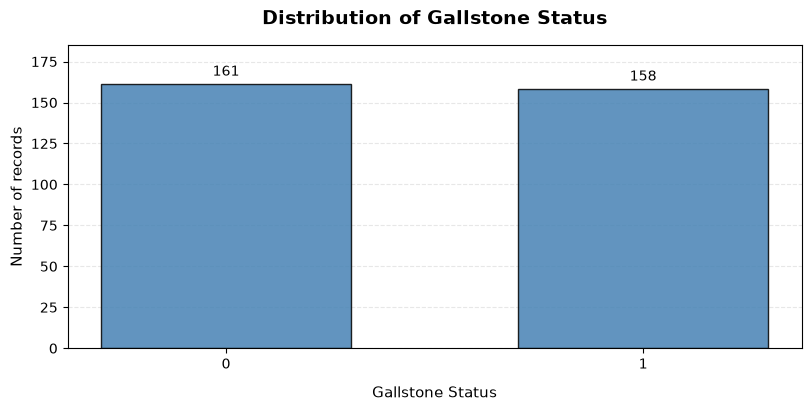

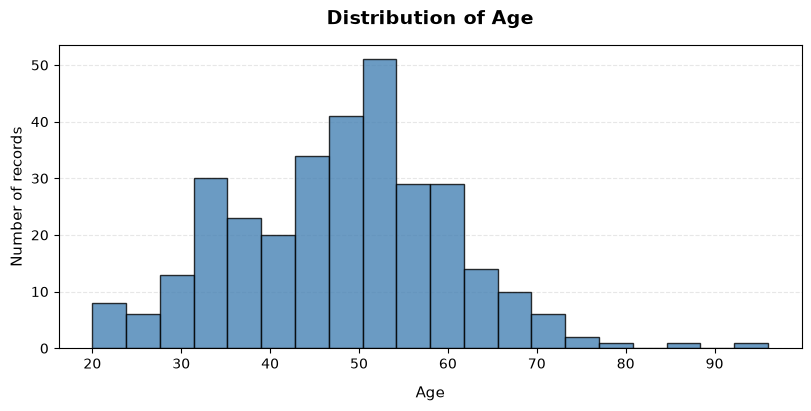

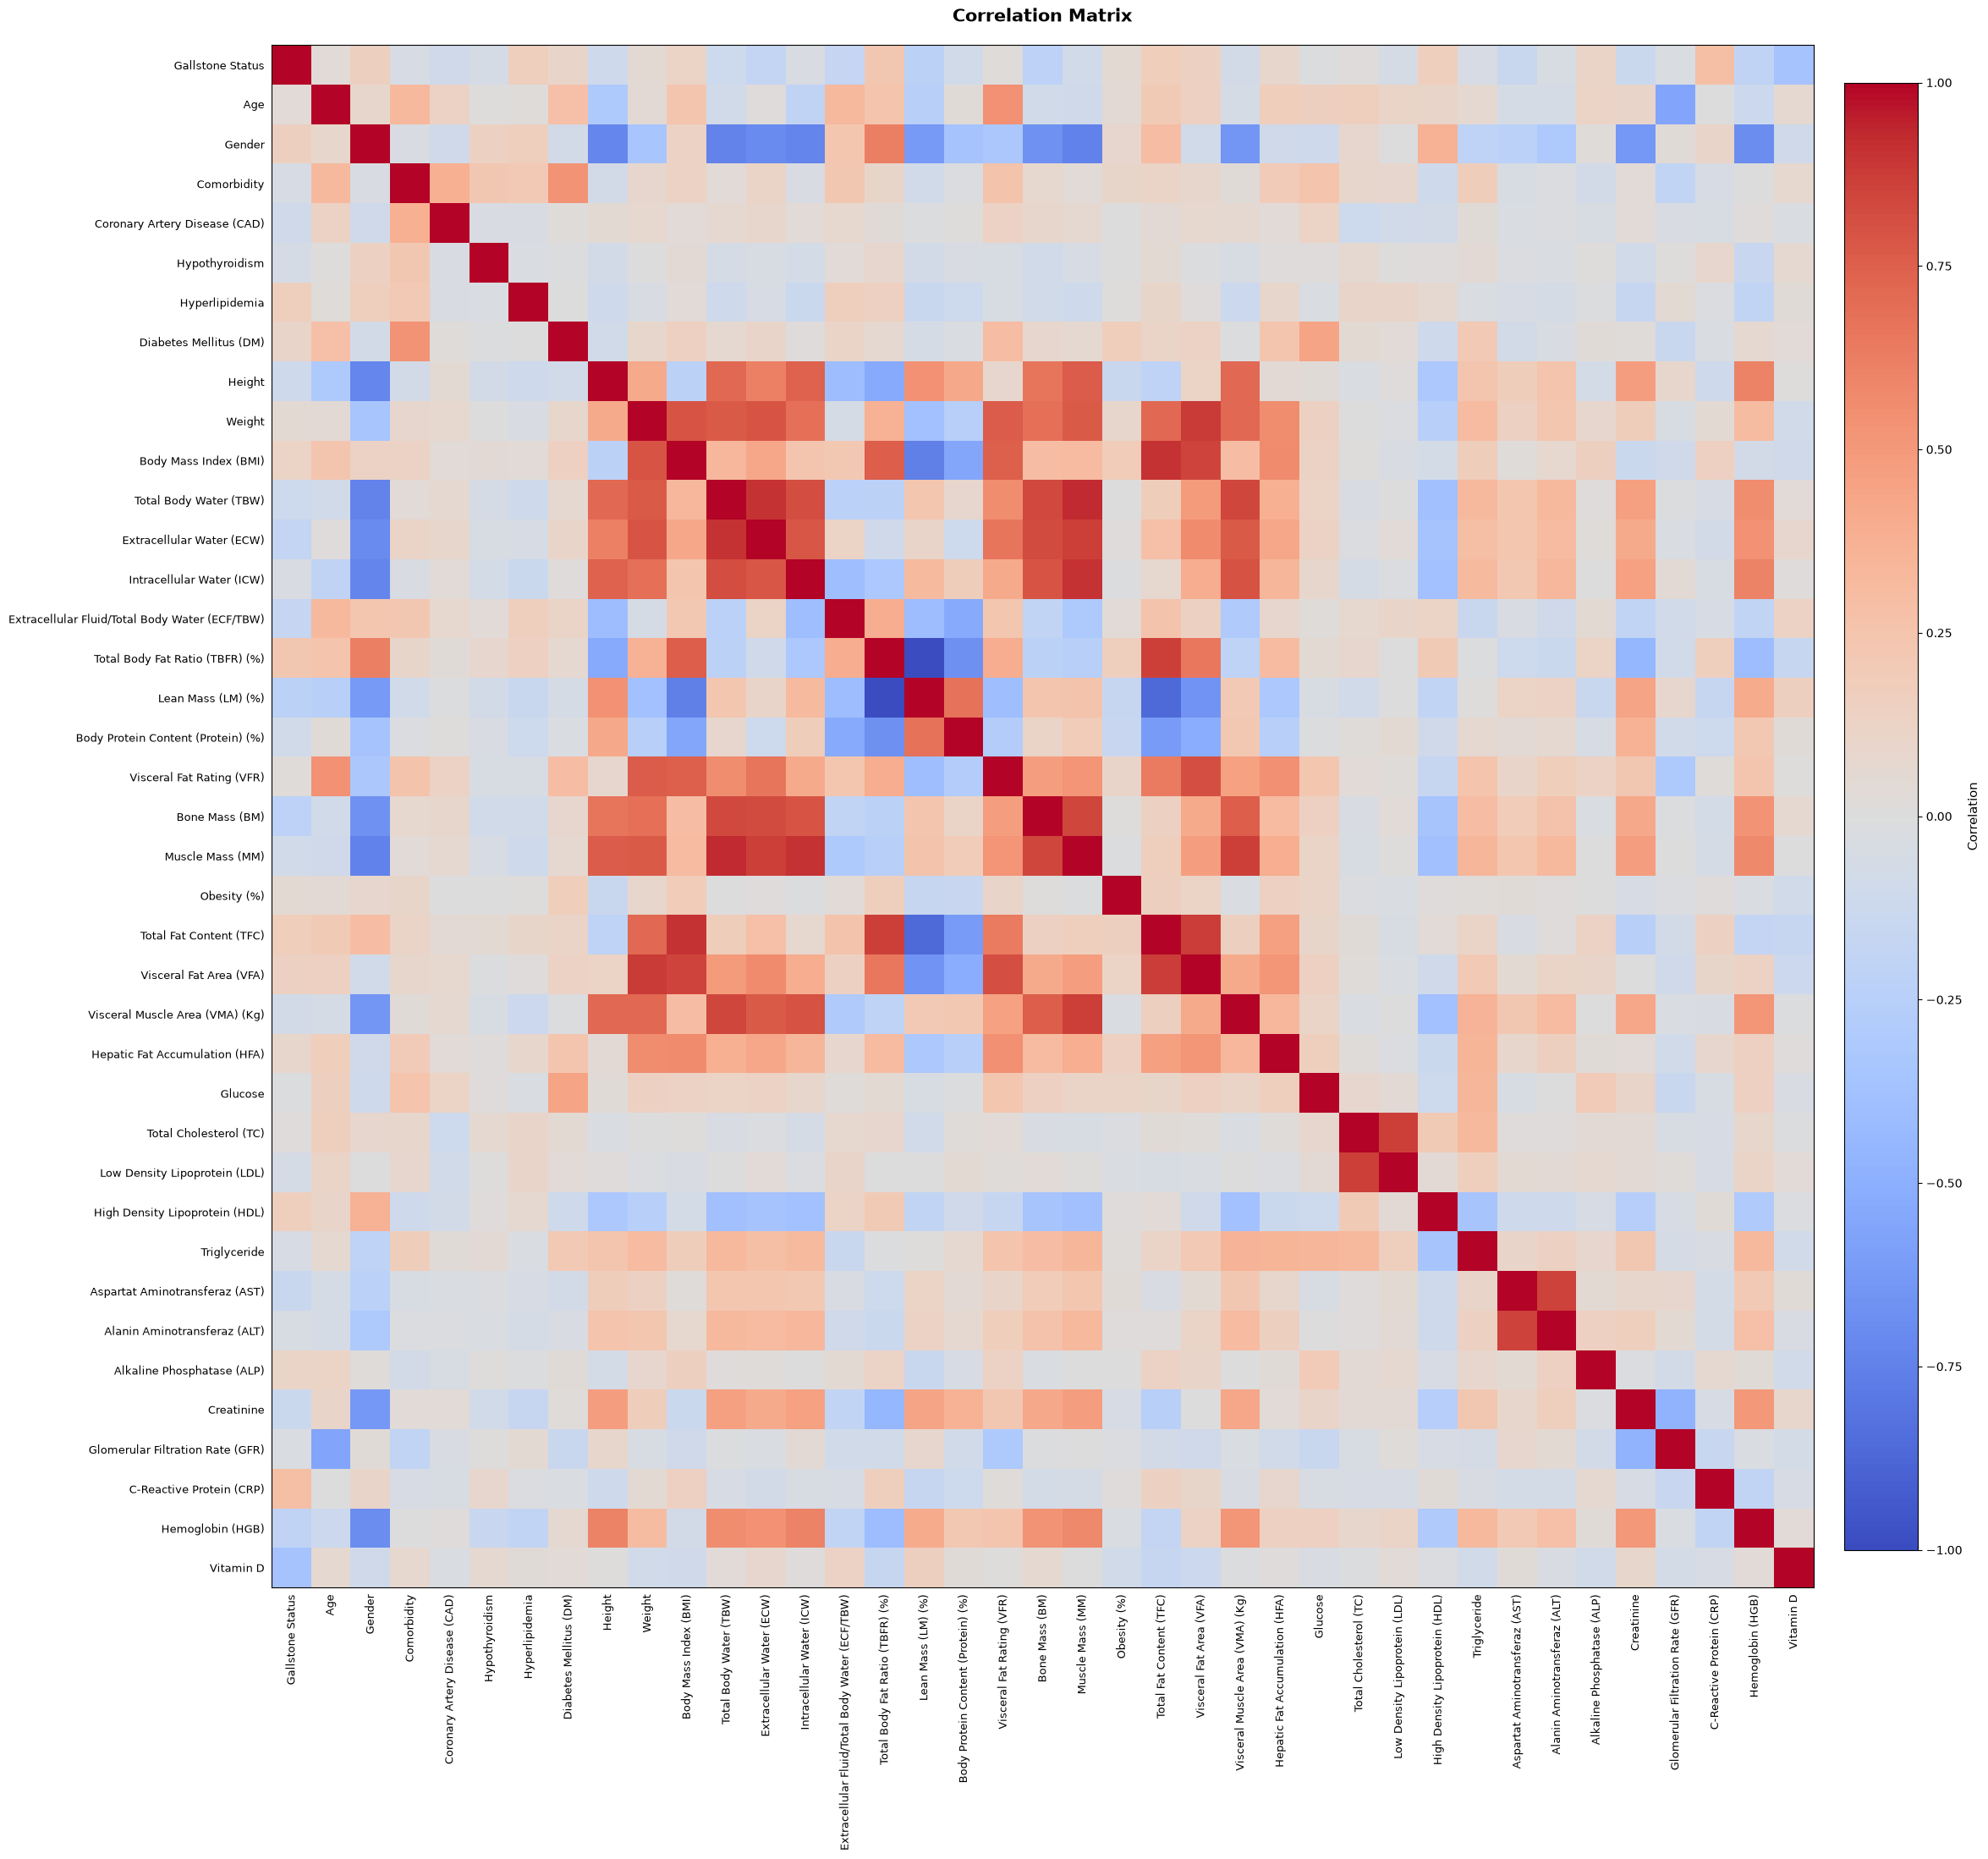

In [58]:
visualizer = DataVisualizer(processed_data)
visualizer.plot_target_distribution(target="Gallstone Status")
plt.show()

visualizer.plot_feature_distribution(feature="Age")
plt.show()

visualizer.plot_correlation_matrix()
plt.show()

## Model training and evaluation

The model uses an 80/20 stratified train/test split. Stratification keeps the two target classes represented in both sets. The random state is fixed so the split can be repeated.

The evaluation focuses on gallstone presence, which is class `0`. Accuracy shows the overall number of correct predictions. Precision shows how many predicted gallstone cases are correct. Recall shows how many actual gallstone cases were found. F1 combines precision and recall, while ROC-AUC measures the ranking of the predicted probabilities.

In [59]:
trainer = XGBoostModelTrainer(processed_data)
model = trainer.train()
metrics = trainer.evaluate(model)

print("Evaluation metrics (gallstones = class 0):")
for name, value in metrics.items():
    print(f"{name}: {value:.3f}")

Training set shape: (255, 38), Test set shape: (64, 38)

Classification report (0 = Gallstones, 1 = No gallstones):
               precision    recall  f1-score   support

   Gallstones       0.75      0.94      0.83        32
No gallstones       0.92      0.69      0.79        32

     accuracy                           0.81        64
    macro avg       0.83      0.81      0.81        64
 weighted avg       0.83      0.81      0.81        64


Confusion matrix (rows = actual; columns = predicted; order = [0, 1]):
[[30  2]
 [10 22]]
Evaluation metrics (gallstones = class 0):
accuracy: 0.812
precision_gallstones: 0.750
sensitivity_gallstones: 0.938
specificity_gallstones: 0.688
f1_gallstones: 0.833
roc_auc_gallstones: 0.850


## Model evaluation plots

The confusion matrix compares predictions with actual labels in the held-out test set. Class 0 is gallstone presence.

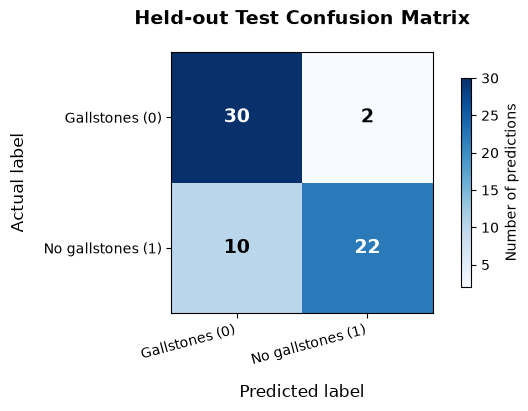

In [60]:
test_predictions = model.predict(trainer.X_test)
visualizer.plot_confusion_matrix(actual=trainer.y_test, predicted=test_predictions)
plt.show()

## SHAP explanations

Permutation SHAP explains the model’s predicted probability of gallstones directly, avoiding the TreeExplainer compatibility issue with newer XGBoost versions. It uses training records as the background and explains held-out test records. Positive contributions increase predicted gallstone probability. The bar plot ranks features by mean absolute contribution; the beeswarm shows the direction and spread of contributions. These are model explanations, not evidence of causation. Permutation SHAP is approximate and can take longer than Tree SHAP.

In [61]:
explanations = trainer.explain(model)

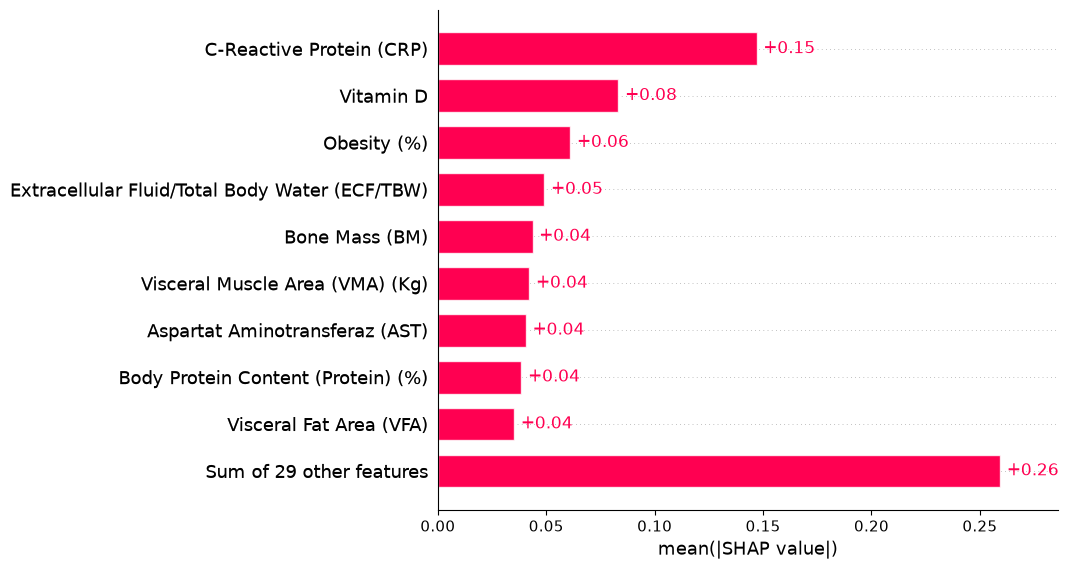

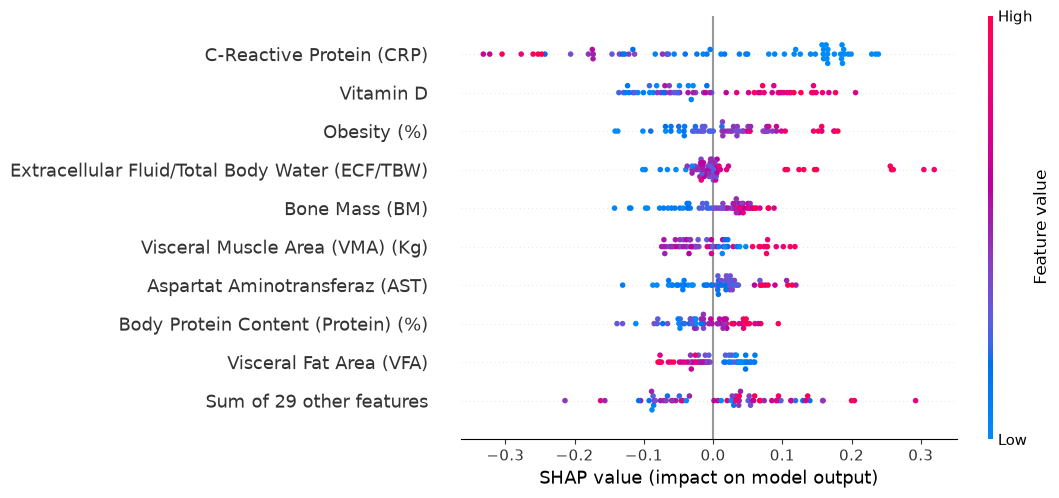

In [62]:
shap.plots.bar(explanations, show=False)
plt.show()

shap.plots.beeswarm(explanations, show=False)
plt.show()

## Discussion

Fix